In [2]:
import pandas as pd

In [3]:
orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")

In [4]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

### Línea: pedidos por mes
Cargar orders y convertir order_purchase_timestamp a datetime.
Filtrar order_status == 'delivered' (opcional).
Crear columna de mes con .dt.to_period('M').
groupby por mes y contar order_id con nunique.
Recortar meses extremos (2016 y sept–oct 2018 casi no tienen datos): buena lección de "mira tus datos antes de graficar".
Graficar mes vs. número de pedidos; título, etiquetas y rotar ticks.

,order_purchase_timestamp,order_id,month
44214,2017-10-04 00:03:23,0c021596b865eb54c02ad64bf7d55aea,2017-10
24325,2018-08-14 17:26:41,f1d6087db90cd2b8feb467f5924d4f08,2018-08
78362,2017-10-04 09:13:51,04132c02a610a19773963143ba1b5bb4,2017-10
91553,2018-08-12 13:25:50,b703b9bca2536eca02a03e9f8f00fc47,2018-08
64569,2018-07-28 13:11:22,738d6dc61c6c4ddc88d8996cec5dadae,2018-07


<Axes: title={'center': 'Numero de ventas por mes'}, xlabel='mes', ylabel='cantidad de ventas'>

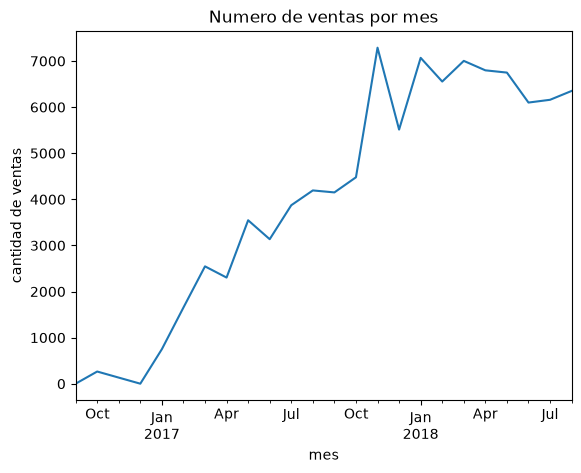

In [8]:
df1= orders[orders["order_status"] == "delivered"]
df1= df1[["order_purchase_timestamp","order_id"]]
df1["month"] = df1["order_purchase_timestamp"].dt.to_period("M")
display(df1.sample(5))
resultado= df1.groupby("month")["order_id"].nunique()
resultado.plot(
kind="line", xlabel="mes", ylabel="cantidad de ventas", title="Numero de ventas por mes")

### Barras horizontales: top 10 categorías por ingreso
1-.Merge order_items + products por product_id.
2-.groupby categoría → suma de price.
3-.Tomar las 10 mayores con .nlargest(10).
Invertir el orden para que la mayor quede arriba y graficar con barh.

<Axes: title={'center': 'Top 10 categorias con mas ventas'}, xlabel='price', ylabel='categoria'>

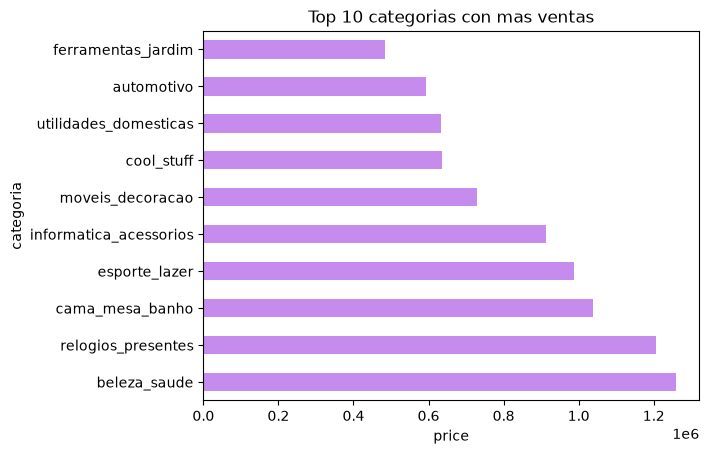

In [12]:
df_merge = pd.merge(order_items, products, on="product_id")
df_grouped = df_merge.groupby("product_category_name")["price"].sum()
df_top10 = df_grouped.nlargest(10)
df_top10.plot(kind="barh", color="#c58ced",xlabel="price", ylabel="categoria", title="Top 10 categorias con mas ventas")

### Histograma: distribución del precio
Usar order_items['price'].
Primer histograma directo: se verá muy sesgado.
Repetir con bins en escala log o con np.log10(price).
Discusión: por qué la media engaña. Marcar media y mediana con axvline.

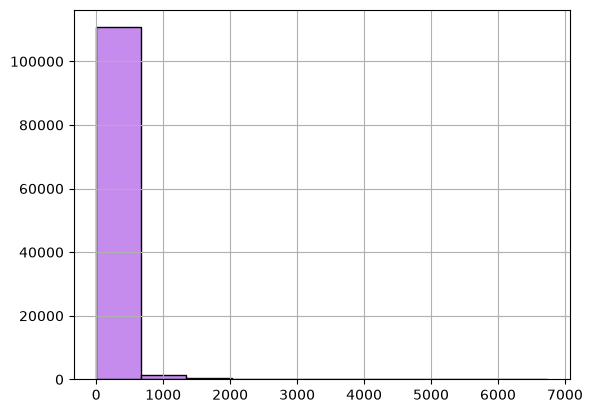

In [13]:
# Usar order_items['price'].Primer histograma directo: se verá muy sesgado.
df5= order_items['price'].hist(bins=10, color="#c58ced", edgecolor="black")

In [14]:
import numpy as np
df5= order_items
df5["log"]= df5["price"].apply(np.log10)

<Axes: ylabel='Frequency'>

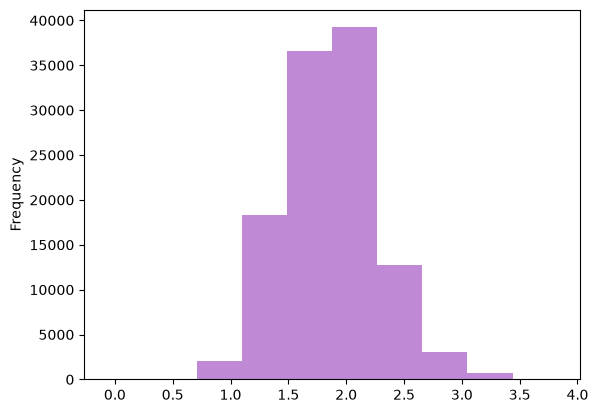

In [15]:
df5["log"].plot(kind="hist", color="#bf89d6")

<Axes: xlabel='order_status'>

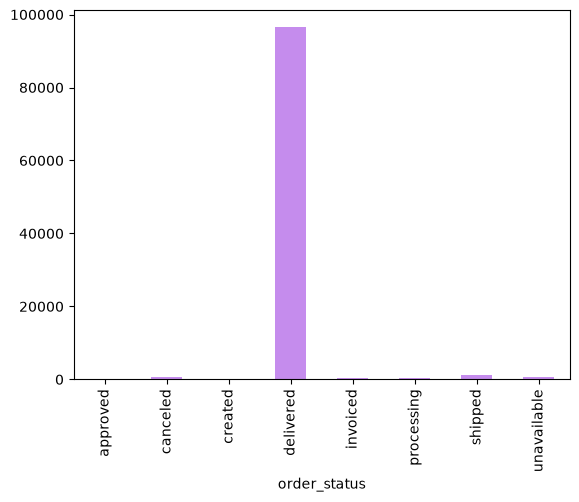

In [11]:
orders.groupby("order_status")["order_id"].count().plot(kind="bar", color="#c58ced")

### Histograma comparativo: días de entrega reales vs. estimados
1-. En orders, convertir a datetime las columnas de compra, entrega real y entrega estimada.
2-. Calcular dias_reales = entregado − compra y dias_estimados = estimado − compra (en .dt.days).
3-. Eliminar NaN (pedidos no entregados).
4-. (profe) Dos histogramas en el mismo eje con alpha=0.5 y leyenda.

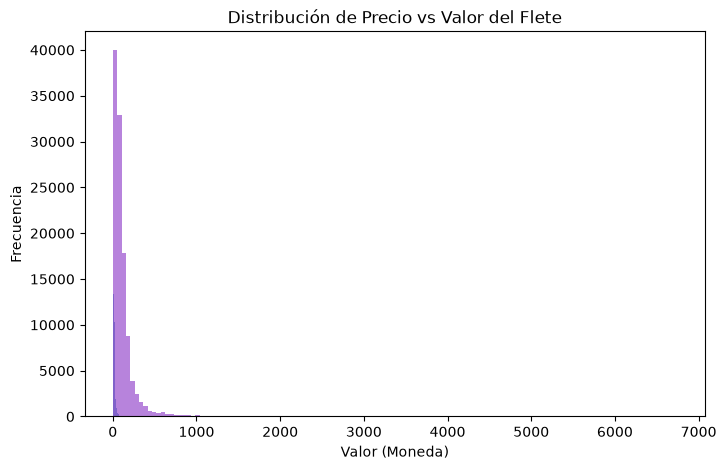

In [18]:
#1
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
orders["order_delivered_carrier_date"] = pd.to_datetime(orders["order_delivered_carrier_date"])
orders["order_estimated_delivery_date"] = pd.to_datetime(orders["order_estimated_delivery_date"])

#2
orders["dif_carrier_vs_estimada"] = (orders["order_delivered_carrier_date"] - orders["order_estimated_delivery_date"]).dt.days
orders["dias_estimados"] = (orders["order_estimated_delivery_date"] - orders["order_purchase_timestamp"]).dt.days

#3
orders = orders.dropna(subset=["dif_carrier_vs_estimada", "dias_estimados"])

#4
import matplotlib.pyplot as plt
linzo, pintura= plt.subplots(figsize=(8, 5))
order_items["freight_value"].plot(kind="hist", ax=pintura, alpha=0.6, label="Valor del Flete", bins=130)

order_items["price"].plot(kind="hist",color="#8730c6", ax=pintura, alpha=0.6, label="Precio", bins=130)

pintura.set_title("Distribución de Precio vs Valor del Flete")
pintura.set_xlabel("Valor (Moneda)")
pintura.set_ylabel("Frecuencia")
plt.show()

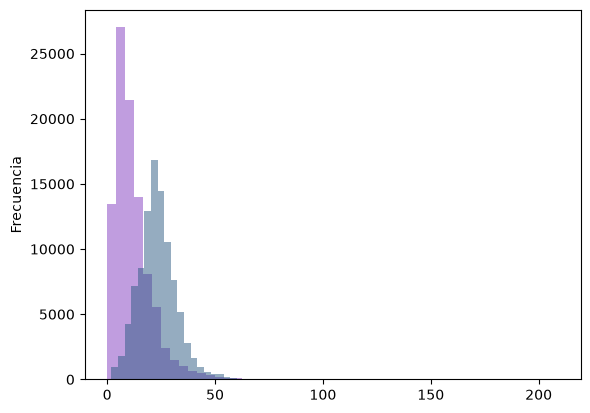

In [21]:
dias_reales = (orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]).dt.days
dias_estimados = (orders["order_estimated_delivery_date"] - orders["order_purchase_timestamp"]).dt.days
dias_reales = dias_reales.dropna()
dias_estimados = dias_estimados.dropna()
ax1 = dias_reales.plot(kind = "hist", color ="#823cc0", alpha = 0.5, bins = 50, label = "Días reales",ylabel = "Frecuencia")
ax2 = dias_estimados.plot(kind= "hist", color ="#2c5a82", alpha = 0.5, bins = 50, label = "Días estimados", ylabel = "Frecuencia")

### Boxplot: calificación vs. días de retraso
En orders, calcular retraso = entregado − estimado en días.
Merge con order_reviews por order_id (quitar duplicados por order_id: hay pedidos con más de una reseña).
Agrupar el retraso por review_score (1–5) → lista de 5 arrays.
Pasar la lista a boxplot con etiquetas 1–5.
Conclusión esperada: las calificaciones de 1 tienen retrasos mucho mayores.

{'whiskers': [<matplotlib.lines.Line2D at 0x18b69287620>,
 'caps': [<matplotlib.lines.Line2D at 0x18b692878c0>,
 'boxes': [<matplotlib.lines.Line2D at 0x18b692874d0>,
 'medians': [<matplotlib.lines.Line2D at 0x18b69287b60>,
 'fliers': [<matplotlib.lines.Line2D at 0x18b69287cb0>,
 'means': []}

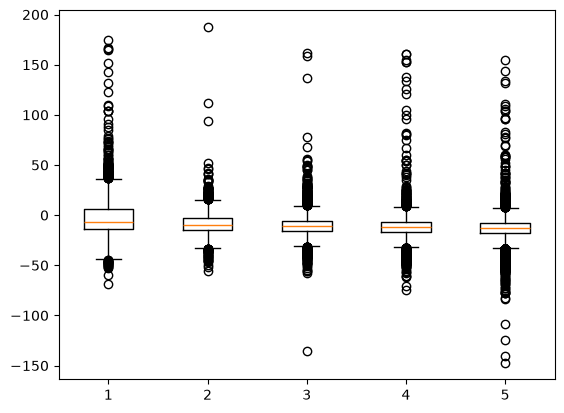

In [23]:
orders["retraso"] = (orders["order_delivered_customer_date"]-orders["order_estimated_delivery_date"]).dt.days
merge = orders.merge(order_reviews, on = "order_id", how = "left").drop_duplicates(subset="order_id")
merge = merge.dropna(subset="retraso")
lista = [merge[merge["review_score"] == calif]["retraso"] for calif in range(1, 6)]
fig, ax = plt.subplots()
ax.boxplot(lista,label=[1,2,3,4,5])

### Barras con error: calificación promedio a tiempo vs. tarde
Usar el mismo merge de la gráfica 5.
Crear columna booleana tarde = retraso > 0.
groupby('tarde') → mean y std de review_score.
Graficar barras con yerr=std.

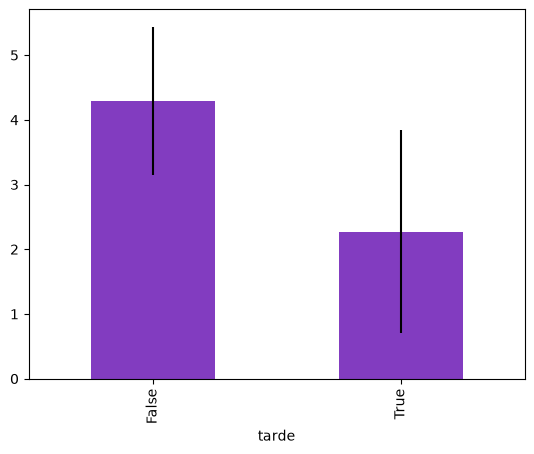

In [25]:
merge["tarde"] = (merge["retraso"]>0)
merge = merge.dropna(subset="retraso")
tarde_con_review = merge.groupby("tarde")["review_score"].agg(["mean","std"])
ax3 = tarde_con_review["mean"].plot(kind="bar",color="#823cc0", yerr = tarde_con_review["std"])

### Pastel / dona: métodos de pago
order_payments → value_counts() de payment_type.
Agrupar not_defined y categorías pequeñas en "otros".
Graficar con autopct='%1.1f%%'; para dona, wedgeprops={'width':0.4}.
Discusión: por qué los pasteles suelen ser mala idea; comparar con la versión en barras.

<Axes: >

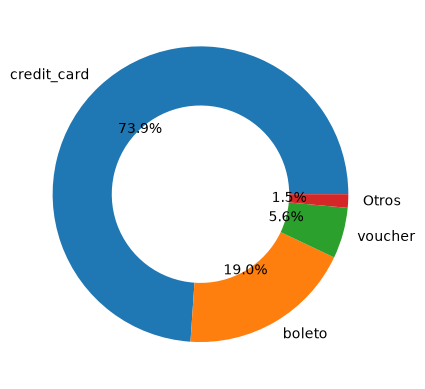

In [27]:
df8 = payments["payment_type"].value_counts().head(3)
df8["Otros"] = payments["payment_type"].value_counts().iloc[3:].sum()
df8.plot(kind = "pie",color=["#823cc0","#2c5a82","pink"], autopct="%1.1f%%", wedgeprops={"width":0.4})

### Barras agrupadas: monto promedio por mensualidades y método de pago
Tomar order_payments.
Crear rangos de payment_installments con pd.cut: 1, 2–3, 4–6, 7–10, más de 10.
pivot_table: index = rango, columns = payment_type, values = payment_value, aggfunc = 'mean'.
Barras agrupadas desplazando cada serie con x + i*ancho (o df.plot(kind='bar')).

<Axes: xlabel='rango de mensualidades', ylabel='valor de pago promedio'>

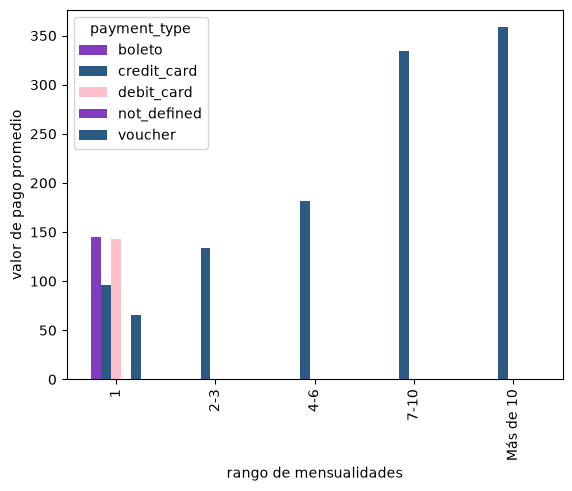

In [28]:
payments["rangos"] = pd.cut(payments["payment_installments"], bins=[0,1,3,6,10,np.inf], labels = ["1","2-3","4-6","7-10","Más de 10"])
pibble = payments.pivot_table(index="rangos",columns="payment_type",values="payment_value",aggfunc="mean")
pibble.plot(kind="bar",color=["#823cc0","#2c5a82","pink"], ylabel = "valor de pago promedio", xlabel = "rango de mensualidades")

### Barras apiladas: estado del pedido por estado de la república
Merge orders + customers por customer_id.
pivot_table: index = customer_state, columns = order_status, values = order_id, aggfunc = 'count', fill_value=0.
Normalizar por fila (dividir entre .sum(axis=1)) para tener porcentajes.
Quedarse con los 10 estados con más pedidos.
Apilar barras con un loop acumulando bottom.

<Axes: xlabel='Estado de orden', ylabel='Proporcion de pedidos'>

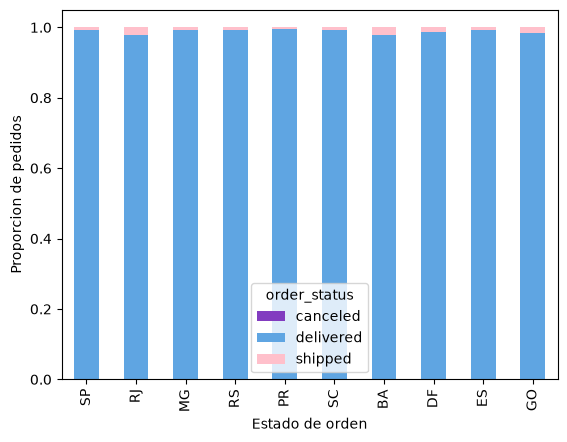

In [31]:
merge1 = orders.merge(customers, on="customer_id", how = "left")
pibble_2 = merge1.pivot_table(index = "customer_state",columns = "order_status",values= "order_id",aggfunc="count",fill_value=0)
pibble2_suma = pibble_2.sum(axis=1)
pibble2_division = pibble_2.div(pibble2_suma,axis=0)
pibble2_division_10 = pibble2_division.loc[pibble2_suma.nlargest(10).index]
pibble2_division_10.plot(kind="bar",color=["#823cc0","#5fa5e2","pink"], stacked="True", xlabel="Estado de orden", ylabel = "Proporcion de pedidos")

### Dispersión: peso del producto vs. costo de envío

1-. Merge order_items + products por product_id.
2-. Tomar product_weight_g y freight_value; quitar NaN.
3-. Muestrear con .sample(3000) (110k puntos saturan la gráfica).
4-. Graficar con alpha bajo; opcionalmente ejes en escala log.
Extra: colorear por price con c= y agregar plt.colorbar().

<Axes: xlabel='freight_value', ylabel='price'>

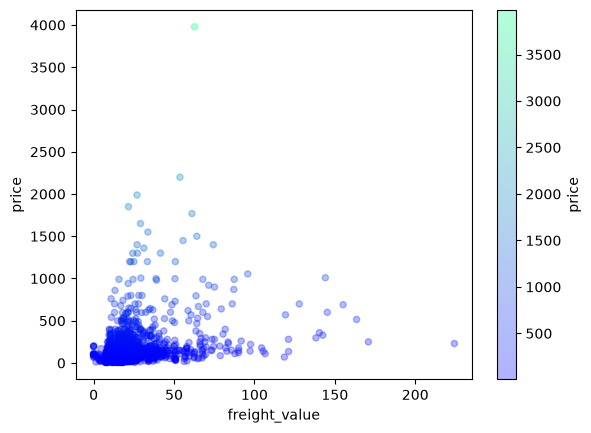

In [32]:
order_items = pd.read_csv("olist_order_items_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")

df = order_items.merge(products, on="product_id", how="left")
df = df.dropna(subset=["product_weight_g", "freight_value"])
muestra = df.sample(n=3000)
muestra.plot(kind="scatter", x="freight_value", y="price", alpha=0.3, c="price", colormap="winter")

### Mapa de calor: pedidos por día de la semana × hora
De order_purchase_timestamp extraer .dt.dayofweek y .dt.hour.
pivot_table: index = día, columns = hora, values = order_id, aggfunc = 'count'.
plt.imshow(pivot, aspect='auto', cmap='YlOrRd').
Etiquetas Lun–Dom en y, 0–23 en x; agregar colorbar.
Extra: escribir valores en las celdas con doble loop de ax.text.

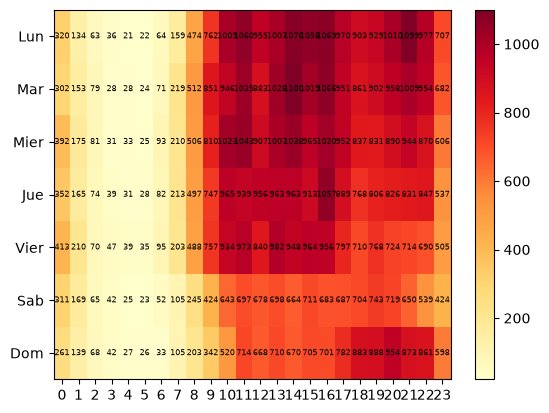

In [33]:
orders["dias_semana"] = orders["order_purchase_timestamp"].dt.dayofweek
orders["horas"] = orders["order_purchase_timestamp"].dt.hour
pibble3 =  orders.pivot_table(index ="dias_semana", columns = "horas", values= "order_id",aggfunc="count")
mapa = plt.imshow(pibble3,aspect="auto",cmap ="YlOrRd" )
plt.yticks(range(7),["Lun","Mar","Mier","Jue","Vier","Sab","Dom"])
plt.xticks(range(24))
plt.colorbar(mapa)
for i in range(7):
    for j in range(24):plt.text(j, i, pibble3.iloc[i, j],  ha="center", va="center",fontsize=6)